# Demo: flujo de delegación del Orquestador Multi-Agente

Este notebook muestra cómo el **Supervisor** reparte el trabajo entre el **Agente de Investigación** (búsqueda en la Vector DB local) y el **Agente de Análisis** (cálculos y sentimiento), y cómo se cierra la conversación pasando por **Síntesis** y **Validación**.

Requisitos: haber ejecutado `pip install -r requirements.txt`, tener `OPENAI_API_KEY` en `.env` y abrir el notebook con el kernel del `.venv` del proyecto. La primera búsqueda descarga el modelo de embeddings e indexa el corpus (unos segundos).

In [7]:
import sys
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)
from IPython.display import Image, Markdown, display

from graph import build_graph
from llm import get_llm
from runner import describe_event, run_query, save_trace

graph = build_graph(get_llm())
print("Grafo compilado. Nodos:", list(graph.get_graph().nodes))

Grafo compilado. Nodos: ['__start__', 'supervisor', 'researcher', 'analyst', 'synthesizer', 'validator', '__end__']


## 1. Topología

`START → supervisor`; el supervisor decide con una arista condicional (`Literal["researcher", "analyst", "synthesizer"]`). Los especialistas siempre vuelven al supervisor; la síntesis pasa por el validador, que termina o devuelve el control al supervisor.

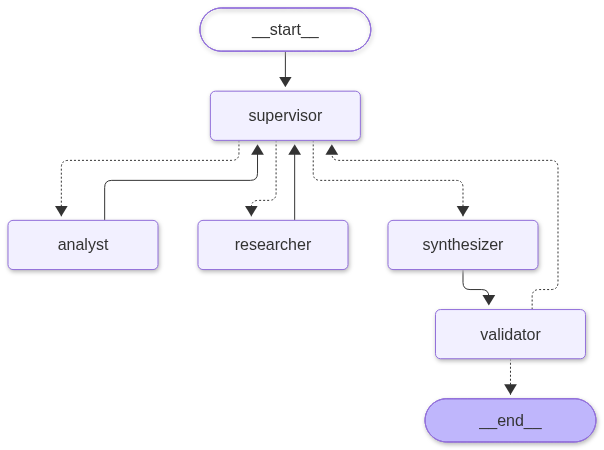

In [8]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:  # draw_mermaid_png usa mermaid.ink: requiere internet
    print(f"Sin PNG ({exc}). Mermaid:\n")
    print(graph.get_graph().draw_mermaid())

## 2. Consulta que obliga a Investigador → Analista → cierre

La consulta pide un **dato documental** (días por antigüedad) y un **cálculo** (promedio y porcentaje). Cada línea impresa es un paso del grafo: la decisión del supervisor con su motivo, y el aporte de cada especialista con las fuentes que realmente recuperó.

In [9]:
def print_event(node, update):
    print(describe_event(node, update), flush=True)

consulta_1 = (
    "Según la política de vacaciones, ¿cuántos días corresponden a empleados con 3, 7 y 12 años "
    "de antigüedad? Calcula el promedio y en qué porcentaje supera el de 12 años al de 3."
)
estado_1 = await run_query(graph, consulta_1, on_event=print_event)
display(Markdown("### Respuesta final\n\n" + estado_1["final_answer"]))

[supervisor · paso 1] → researcher
    motivo: La consulta requiere evidencia factual sobre la política de vacaciones y además cálculos (promedio y porcentaje). No hay contribuciones registradas todavía, así que falta que el researcher extraiga los días correspondientes a 3, 7 y 12 años desde el …
    instrucción: Busca en la política de vacaciones los días de vacaciones que corresponden a empleados con 3, 7 y 12 años de antigüedad. Devuelve los tres valores exactos y cita la fuente con el formato [Fuente: archivo].
[researcher] 3 años: 14 días naturales de vacaciones por año calendario. [Fuente: politica_vacaciones.md] 7 años: 21 días naturales de vacaciones por año calendario. [Fuente: politica_vacaciones.md] 12 años: 28 días naturales de vacaciones por año calendario. [Fuente: politica_vacaciones.md]
    fuentes recuperadas: politica_vacaciones.md, onboarding_nuevos_empleados.md, politica_teletrabajo.md
[supervisor · paso 2] → analyst
    motivo: La cobertura factual ya está complet

### Respuesta final

Según la política de vacaciones, corresponden **14 días** a los empleados con **3 años** de antigüedad, **21 días** a los de **7 años** y **28 días** a los de **12 años**. El **promedio** es de **21.0 días**, y el de **12 años** supera al de **3 años** en **100.0%**. [Fuente: politica_vacaciones.md]

- **3 años:** 14 días naturales de vacaciones por año calendario. [Fuente: politica_vacaciones.md]
- **7 años:** 21 días naturales de vacaciones por año calendario. [Fuente: politica_vacaciones.md]
- **12 años:** 28 días naturales de vacaciones por año calendario. [Fuente: politica_vacaciones.md]
- **Promedio:** 21.0 días. [Fuente: politica_vacaciones.md]
- **Supera en porcentaje el de 12 años al de 3 años:** 100.0%. [Fuente: politica_vacaciones.md]

### Estado compartido: quién aportó qué

`contributions` se acumula con el reducer `operator.add`: ningún agente pisa el trabajo de otro y cada aporte guarda la instrucción que lo originó y el paso del supervisor.

In [10]:
for c in estado_1["contributions"]:
    fuentes = ", ".join(c["sources"]) or "-"
    print(f"paso {c['iteration']:>2} | {c['agent']:<11} | fuentes: {fuentes}")
    print(f"          instrucción: {c['instruction'][:110]}")
print("\nDelegaciones:", " → ".join(d["next_agent"] for d in estado_1["decisions"]))
print("Traza guardada en", save_trace(consulta_1, estado_1))

paso  1 | researcher  | fuentes: politica_vacaciones.md, onboarding_nuevos_empleados.md, politica_teletrabajo.md
          instrucción: Busca en la política de vacaciones los días de vacaciones que corresponden a empleados con 3, 7 y 12 años de a
paso  2 | analyst     | fuentes: -
          instrucción: Con los datos ya obtenidos por el researcher: 3 años = 14 días, 7 años = 21 días, 12 años = 28 días, calcula: 
paso  3 | synthesizer | fuentes: politica_vacaciones.md
          instrucción: Redacta la respuesta final en español, incluyendo: días para 3, 7 y 12 años de antigüedad; el promedio calcula
paso  3 | validator   | fuentes: -
          instrucción: Validar la respuesta final

Delegaciones: researcher → analyst → synthesizer
Traza guardada en C:\Users\juanl\OneDrive\Documentos\GIT_REPOSITORIOS\coderhouse_entregables\Pre-entrega6\traces\trace_20261107_025415.json


## 3. Segunda consulta: sentimiento + variación porcentual

Aquí el analista usa `analizar_sentimiento` sobre los comentarios que trajo el investigador y `variacion_porcentual` para el eNPS.

In [11]:
consulta_2 = (
    "Busca los comentarios abiertos de la encuesta de clima 2025 y analiza su sentimiento. "
    "Además, calcula la variación porcentual del eNPS respecto de 2024."
)
estado_2 = await run_query(graph, consulta_2, on_event=print_event)
display(Markdown("### Respuesta final\n\n" + estado_2["final_answer"]))
print("\nDelegaciones:", " → ".join(d["next_agent"] for d in estado_2["decisions"]))
print("Traza guardada en", save_trace(consulta_2, estado_2))

[supervisor · paso 1] → researcher
    motivo: La consulta exige evidencia documental sobre los comentarios abiertos de la encuesta de clima 2025 y el valor de eNPS 2024/2025, además de un análisis de sentimiento y una variación porcentual. No hay contribuciones registradas, así que aún no se cum…
    instrucción: Busca en la base documental interna la siguiente evidencia para la encuesta de clima 2025: 1) los comentarios abiertos disponibles, citando cada hallazgo con [Fuente: archivo]; 2) el valor de eNPS 2025 y el de 2024, también con [Fuente: archivo]. Si …
[researcher] Comentarios abiertos disponibles en la encuesta de clima 2025: 1. "La flexibilidad del teletrabajo es excelente y me permite organizar mejor mi semana." [Fuente: encuesta_clima_2025.md] 2. "Mi líder me da apoyo constante y valoro mucho las oportunidades de crecimiento." [Fuente: encuesta_clima_2025.md] 3. "En Soporte la sobrecarga de tickets es terrible y el estrés del equipo es muy alto." [Fuente…
    fuentes recup

### Respuesta final

Aquí tienes el análisis de los comentarios abiertos de la encuesta de clima 2025 y la variación del eNPS respecto de 2024.

- **Comentario 1:** “La flexibilidad del teletrabajo es excelente y me permite organizar mejor mi semana.”  
  **Sentimiento:** positivo. [Fuente: encuesta_clima_2025.md]

- **Comentario 2:** “Mi líder me da apoyo constante y valoro mucho las oportunidades de crecimiento.”  
  **Sentimiento:** positivo. [Fuente: encuesta_clima_2025.md]

- **Comentario 3:** “En Soporte la sobrecarga de tickets es terrible y el estrés del equipo es muy alto.”  
  **Sentimiento:** negativo. [Fuente: encuesta_clima_2025.md]

- **Comentario 4:** “Las herramientas internas son lentas y los procesos de compras son confusos.”  
  **Sentimiento:** negativo. [Fuente: encuesta_clima_2025.md]

- **Comentario 5:** “El onboarding fue claro y me sentí bienvenido desde el primer día.”  
  **Sentimiento:** positivo. [Fuente: encuesta_clima_2025.md]

- **Comentario 6:** “No hay reconocimiento por el trabajo extra y la comunicación entre áreas es pésima.”  
  **Sentimiento:** negativo. [Fuente: encuesta_clima_2025.md]

- **Comentario 7:** “Los beneficios son buenos, aunque el salario quedó por debajo del mercado.”  
  **Sentimiento:** positivo. [Fuente: encuesta_clima_2025.md]

- **Comentario 8:** “Estoy contento con el equipo y orgulloso de los proyectos que lanzamos este año.”  
  **Sentimiento:** positivo. [Fuente: encuesta_clima_2025.md]

- **Tono general:** predominan los comentarios **positivos**; en el análisis se registraron **5 positivos, 0 neutrales y 3 negativos**, con **62.5% positivos**.  

- **Variación porcentual del eNPS 2025 vs 2024:**  
  - eNPS 2025 = **21** [Fuente: encuesta_clima_2025.md]  
  - eNPS 2024 = **12** [Fuente: encuesta_clima_2025.md]  
  - Cálculo: **(21 - 12) / 12 * 100 = 75%**  

**Resultado:** el eNPS de 2025 subió **75%** respecto de 2024.


Delegaciones: researcher → analyst → synthesizer
Traza guardada en C:\Users\juanl\OneDrive\Documentos\GIT_REPOSITORIOS\coderhouse_entregables\Pre-entrega6\traces\trace_20261107_025429.json


## 4. Condición de parada: el "supervisor infinito"

Para ver la guarda sin gastar tokens, usamos un LLM falso cuyo supervisor **siempre** pide más investigación. Después de `MAX_REVISIONS` refinamientos, la guarda en código fuerza la síntesis.

In [12]:
from langchain_core.messages import AIMessage

from config import MAX_REVISIONS
from tests.fakes import ScriptedChatModel, decide

indeciso = build_graph(
    ScriptedChatModel(responses=[decide("researcher", "Busca un poco más", "Nunca es suficiente")]),
    researcher_llm=ScriptedChatModel(responses=[AIMessage("Sin datos nuevos.")]),
    synthesizer_llm=ScriptedChatModel(responses=[AIMessage("Respuesta con la información disponible.")]),
)
estado_3 = await run_query(indeciso, "Consulta de prueba", on_event=print_event)
print(f"\nMAX_REVISIONS = {MAX_REVISIONS} → delegaciones:", [d["next_agent"] for d in estado_3["decisions"]])

[supervisor · paso 1] → researcher
    motivo: Nunca es suficiente
    instrucción: Busca un poco más
[researcher] Sin datos nuevos.
    fuentes recuperadas: ninguna
[supervisor · paso 2] → researcher
    motivo: Nunca es suficiente
    instrucción: Busca un poco más
[researcher] Sin datos nuevos.
    fuentes recuperadas: ninguna
[supervisor · paso 3] → researcher
    motivo: Nunca es suficiente
    instrucción: Busca un poco más
[researcher] Sin datos nuevos.
    fuentes recuperadas: ninguna
[supervisor · paso 4] → synthesizer (forzado por guarda)
    motivo: researcher alcanzó el máximo de 2 refinamientos. Se fuerza la síntesis.
    instrucción: Sintetiza con la información disponible e indica qué quedó sin resolver.
[synthesizer] Respuesta con la información disponible.
[validator] Respuesta aprobada.

MAX_REVISIONS = 2 → delegaciones: ['researcher', 'researcher', 'researcher', 'synthesizer']
